# How much should you trust a model's score?

Every model ships with a number. This notebook shows, with data whose truth is known, how far that number can be
from the model's real performance, and which habits make it worse. The data comes from simulations, so for every
model we also know its true score on 100,000 fresh examples.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from evallab import config, leakage, regression, truth

R = config.RESULTS
pd.set_option("display.precision", 3)

## 1. The wrong way to cross-validate (live)

Fifty examples, 5,000 random features, and labels that are pure coin flips: no model can beat 50% error. If we
first keep the 100 features most related to the label *using all fifty labels*, then cross-validate, the score
looks excellent. The selection has already seen the test folds.

In [2]:
pd.DataFrame([leakage.wrong_vs_right(seed) for seed in range(10)]).describe().loc[["mean", "min", "max"]]

,"wrong way (select, then CV)",right way (select inside each fold)
mean,0.008,0.48
min,0.000,0.42
max,0.040,0.56


The fix is to treat feature selection as part of the model and redo it inside every fold (a scikit-learn
`Pipeline`). Then the estimate is honest: about 50%.

## 2. Leakage in three forms (full simulation)

In [3]:
l4 = json.loads((R / "l4_leakage.json").read_text())
pd.concat({k: pd.DataFrame(v["results"]).T[["mean", "p10", "p90"]] for k, v in l4.items()})

mean    p10    p90
4a_wrong_way wrong way (select, then CV)          0.013  0.000  0.040
             right way (select inside each fold)  0.487  0.420  0.562
4b_grouped   random K-fold                        0.729  0.694  0.763
             group K-fold                         0.663  0.608  0.711
             truth (new patients)                 0.680  0.662  0.694
4c_time      shuffled K-fold                      0.018 -0.034  0.061
             contiguous K-fold                   -0.292 -0.391 -0.196
             purged + embargo K-fold             -0.297 -0.395 -0.202
             walk-forward                        -0.393 -0.550 -0.225
             truth (fresh series)                -0.203 -0.261 -0.153

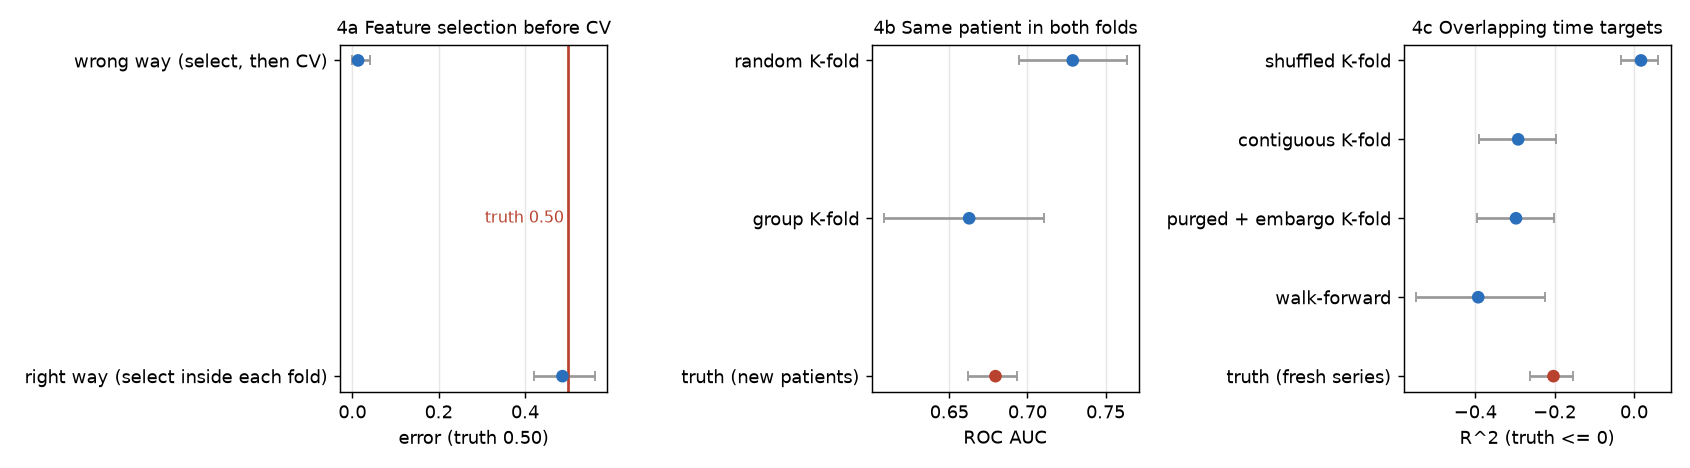

In [4]:
display(Image(str(config.FIGURES / "l4_leakage.png")))

- **Same patient in both folds**: random K-fold lets the model recognise patients it has already seen.
  Group K-fold matches what happens with new patients.
- **Overlapping time targets**: shuffled folds put near-copies of each test row into training. On a series with
  nothing to predict, shuffled CV reports a small edge; the model actually loses.

## 3. Even honest cross-validation is noisy

In [5]:
l3 = json.loads((R / "l3_estimators.json").read_text())
print(f"best possible error {l3['bayes_error']:.3f}; true error of fitted models {l3['mean_truth']:.3f} "
      f"(sd {l3['sd_truth']:.3f} across training sets)")
pd.DataFrame(l3["methods"]).T[["bias", "sd_of_gap", "corr_with_truth"]]

best possible error 0.239; true error of fitted models 0.270 (sd 0.009 across training sets)


,bias,sd_of_gap,corr_with_truth
training error,-0.066,0.033,0.153
holdout 70/30,0.010,0.061,0.075
5-fold CV,0.007,0.036,0.172
10-fold CV,0.003,0.036,0.184
5x5-fold CV,0.009,0.034,0.134
.632 bootstrap,-0.008,0.032,0.148


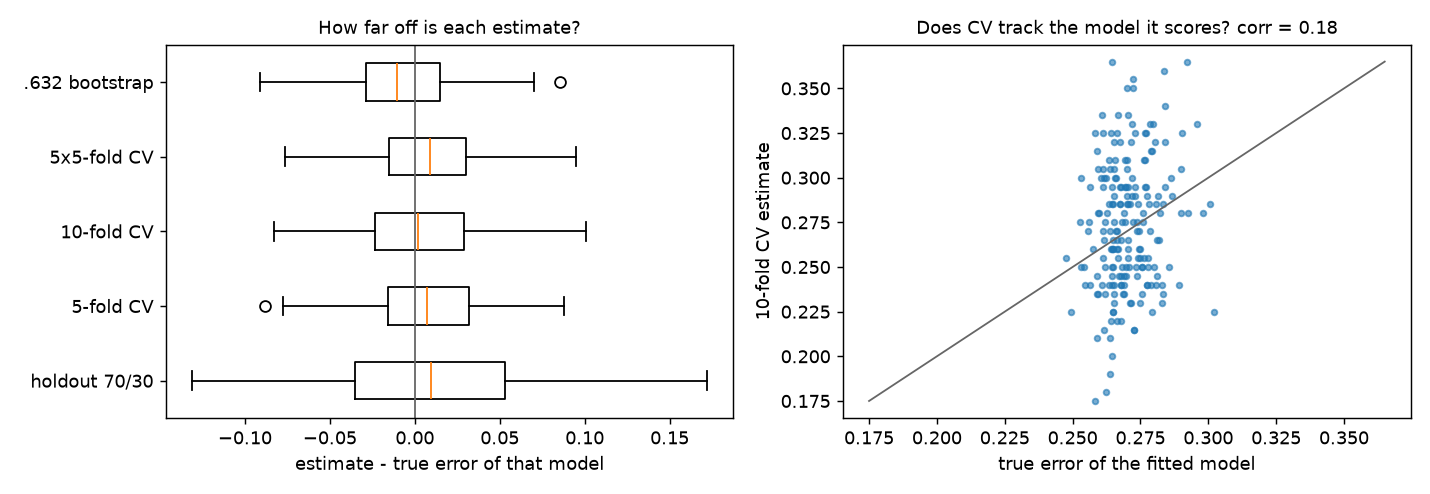

In [6]:
display(Image(str(config.FIGURES / "l3_estimators.png")))

A 10-fold CV score is right on average but typically several points off for any one training set, and it
hardly moves with the error of the particular model you trained (right panel). Treat it as an estimate with an
error bar, and compare models on the same folds.

## 4. Regression: the metric decides the winner

In [7]:
l2 = json.loads((R / "l2_regression.json").read_text())
t = pd.DataFrame(l2["2a_metric_choice"]).T
t[["RMSE", "MAE", "MAPE", "pinball 0.9", "mean bias"]]

,RMSE,MAE,MAPE,pinball 0.9,mean bias
squared error (mean),23.541,12.778,0.574,6.277,0.280
absolute error (median),23.312,11.881,0.473,7.344,-3.509
MAPE-weighted (low median),27.640,13.263,0.398,10.777,-10.365
quantile 0.9,30.994,20.684,1.161,3.945,15.993
"log target, exp back",23.360,12.029,0.471,7.337,-3.308
oracle: mean,21.949,11.909,0.533,5.937,0.044
oracle: median,22.569,11.475,0.443,7.223,-3.714
oracle: mape,25.810,12.669,0.381,10.185,-9.627
oracle: quantile,35.329,23.411,1.268,3.592,20.283


Rows starting with `oracle` use the true distribution: they are the best possible prediction for each
metric. Note the MAPE oracle sits *below* the median (negative bias): MAPE rewards forecasting low.

## 5. R² depends on the data, not just the model (live)

In [8]:
pd.DataFrame(regression.r2_range(n=50_000))

,"narrow x, U(-1, 1)","wide x, U(-3, 3)"
RMSE,1.004,0.998
R2,0.569,0.923


## 6. Does an 80% interval contain 80%?

In [9]:
pd.DataFrame(l2["2c_intervals"]).T

,coverage,"coverage, quiet third","coverage, middle third","coverage, noisy third",mean width
naive: prediction +/- 1.28 RMSE,0.832,0.994,0.858,0.645,4.260
"quantile regression (10%, 90%)",0.740,0.729,0.749,0.743,3.389
split conformal (constant width),0.794,0.987,0.809,0.587,3.756
conformalized quantile (CQR),0.803,0.840,0.796,0.774,3.737
oracle (true 10%-90%),0.800,0.799,0.804,0.798,3.597


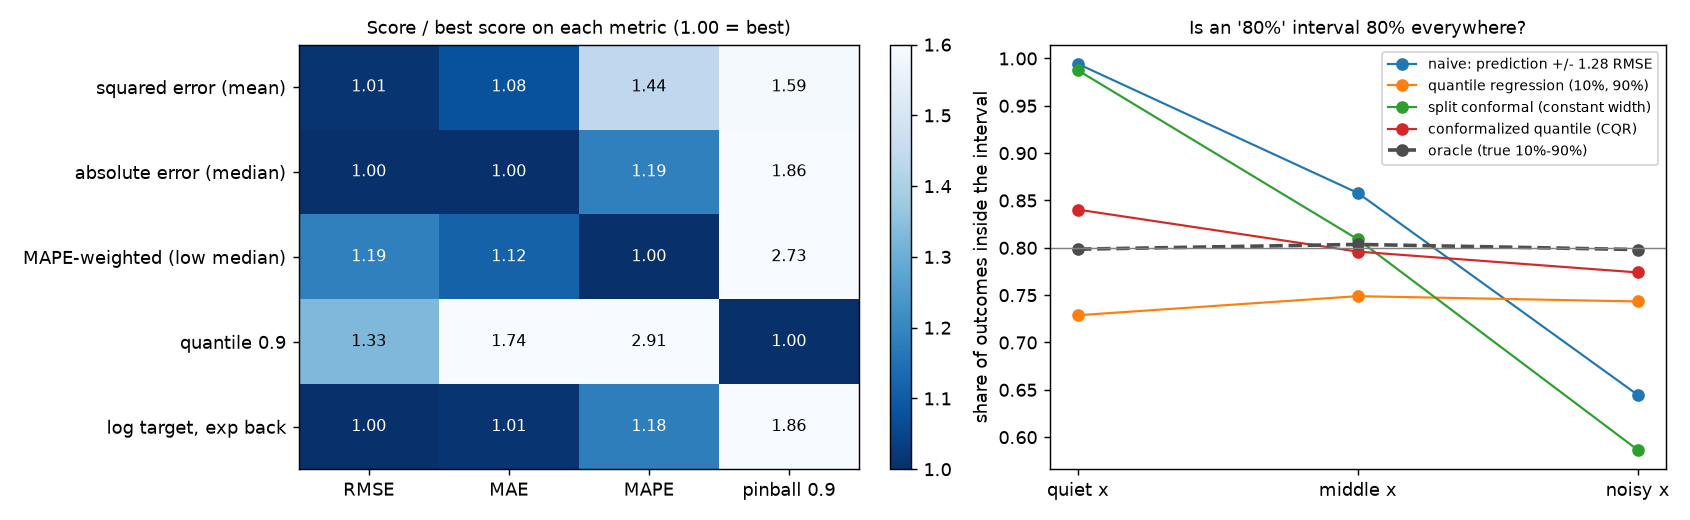

In [10]:
display(Image(str(config.FIGURES / "l2_regression.png")))

Overall coverage can be right while the interval is far too wide where things are calm and too narrow where
risk is highest. Check coverage by segment. Conformalized quantile regression gets closest to the true interval.

## 7. Real data: California housing

In [11]:
pd.DataFrame(l2["2d_california"]).T[["RMSE", "MAE", "MAPE", "pinball 0.9", "R2"]]

,RMSE,MAE,MAPE,pinball 0.9,R2
squared error (mean),0.458,0.303,0.171,0.152,0.843
absolute error (median),0.483,0.304,0.161,0.174,0.825
MAPE-weighted (low median),0.535,0.328,0.158,0.226,0.785
quantile 0.9,0.737,0.556,0.366,0.090,0.592
"log target, exp back",0.469,0.301,0.158,0.169,0.835


In [12]:
cap = l2["2d_cap"]
print(f"{cap['capped_rows']} of {cap['n']} homes are recorded at the $500k cap (true price unknown, higher)")
pd.DataFrame(cap["by_model"]).T

992 of 20640 homes are recorded at the $500k cap (true price unknown, higher)


,mean error on capped rows,MAE on capped rows,MAE on the rest
squared error (mean),-0.532,0.584,0.289
absolute error (median),-0.615,0.641,0.287
MAPE-weighted (low median),-0.886,0.927,0.298
quantile 0.9,-0.183,0.252,0.572
"log target, exp back",-0.607,0.690,0.282
